# Expected shortfall backtests: Acerbi-Szekely with simulated critical values, Du-Escanciano and McNeil-Frey

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 03 of this topic (the exceedance backtests)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- explain why a count of VaR exceedances cannot test an expected shortfall, and what the Acerbi-Szekely statistics $Z_1$ and $Z_2$ measure instead;
- compute $Z_2$ by hand from losses, VaR and ES, and obtain the committed value;
- say what the engine asks the caller to supply to get a critical value, which null Contraste supplies, and why the critical values differ from model to model;
- compare each model's simulated critical value with the published reference point of $-0.70$ and $-1.8$, and say what that reference is and is not;
- run the Du-Escanciano and McNeil-Frey tests on a model whose predictive distribution is known, and read what each adds to $Z_2$.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# The engine's light values, in the words this notebook prints
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The ES tests need the realised loss of every day, so the notebook works on the two windows of case C11 that commit it: `fx-2008` (the euro against the dollar, 251 days) and `rates-2022` (a 10-year Treasury position, 249 days), both built on `mirror-allowed` series. For each of the 17 models and each tail level the files hold the VaR and the ES (positive loss numbers) and, for the models that forecast an ES, the committed Acerbi-Szekely result with the histogram of its simulated null. `equity-2007-09` is read for its committed rows only: its returns are derived-only.

Three rungs do not forecast an ES (`cf-rolling`, `caviar-sav`, `caviar-as`), so the ES tests do not apply to them and the engine would return `not_evaluated`; the notebook skips them. The next cell loads the files and lists which models have an ES.

In [2]:
# Load the two windows that commit the realised losses, plus the equity crisis for its committed rows, and list the models with an ES
ROOT = Path("../../..").resolve()
docs = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in ("fx-2008", "rates-2022", "equity-2007-09")}
print("committed rows baked by riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

fx = docs["fx-2008"]["outputs"]
models = {m["model_id"]: m for m in fx["models"]}
with_es = [mid for mid, m in models.items() if all(lv["es_status"] == "forecast" for lv in m["by_level"])]
print("models with an ES:", len(with_es), "of", len(models))
print("without an ES:", [mid for mid in models if mid not in with_es])
loss = np.array(fx["grid"]["realised_loss"]["loss"])
print("fx-2008: realised losses", loss.size, "| tail levels", [lv["alpha"] for lv in fx["levels"]])

committed rows baked by riskvalidation 0.7.0 | installed 0.9.0
models with an ES: 14 of 17
without an ES: ['cf-rolling', 'caviar-sav', 'caviar-as']
fx-2008: realised losses 251 | tail levels [0.01, 0.025]


## Method

### Step 1: why ES needs its own test, and the statistics $Z_1$ and $Z_2$

The expected shortfall is a statement about **how large** the losses are when the VaR is exceeded. The number of exceedances says nothing about their size: two models with the same VaR and the same count can have very different ES, and only one of them is right. Acerbi and Szekely (2014) test the ES with statistics built from the size of the loss on the exceedance days relative to the forecast ES. With $X_t = -\text{loss}_t$, $I_t = \mathbb 1\{\text{loss}_t > \text{VaR}_t\}$ and $N_T = \sum_t I_t$:

$$Z_1 = \frac{1}{N_T}\sum_{t=1}^{T}\frac{X_t\,I_t}{\mathrm{ES}_t} + 1, \qquad Z_2 = \sum_{t=1}^{T}\frac{X_t\,I_t}{T\,\alpha\,\mathrm{ES}_t} + 1$$

$Z_1$ averages, over the exceedance days only, the ratio of the realised loss to the forecast ES: it is 0 when the losses are, on average, as large as the ES says, and negative when they are larger. $Z_2$ replaces $N_T$ by the expected count $T\alpha$, so it also penalises a **wrong number** of exceedances. Both have expectation 0 under the null that the forecasts are right, and both are negative when risk is underestimated. The cell computes both by hand for every model with an ES, at both levels, and sets $Z_2$ beside the committed value.

In [3]:
# Z1 and Z2 by hand from the losses, VaR and ES of each model with an ES, and Z2 against the committed value
committed_bt = {(x["model_id"], x["alpha"]): x for x in fx["es_backtests"]}
worst = 0.0
print(f"{'model':11s} {'alpha':>6s} {'exceed.':>7s} {'Z1':>9s} {'Z2':>9s} {'Z2 committed':>13s}")
for mid in with_es:
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        exceed = loss > var
        z1 = -(loss[exceed] / es[exceed]).mean() + 1.0 if exceed.any() else float("nan")
        z2 = -(loss[exceed] / es[exceed]).sum() / (loss.size * alpha) + 1.0
        committed = committed_bt[(mid, alpha)]["realised"]
        worst = max(worst, abs(z2 - committed))
        if mid in ("hs-250", "ewma", "garch-t", "dn-rolling", "evt-mf", "gas-fz-2"):
            print(f"{mid:11s} {alpha:6.3f} {int(exceed.sum()):7d} {z1:9.4f} {z2:9.4f} {committed:13.4f}")
print(f"largest difference between Z2 by hand and the committed value, all {len(with_es)} models and both levels: {worst:.2e}")

model        alpha exceed.        Z1        Z2  Z2 committed
hs-250       0.010      10   -0.0691   -3.2592       -3.2592
hs-250       0.025      13   -0.1350   -1.3513       -1.3513
dn-rolling   0.010      23   -0.2444  -10.4033      -10.4033
dn-rolling   0.025      35   -0.2394   -5.9131       -5.9131
ewma         0.010       3   -0.1242   -0.3437       -0.3437
ewma         0.025       8   -0.0323   -0.3160       -0.3160
garch-t      0.010       3   -0.0402   -0.2432       -0.2432
garch-t      0.025       7   -0.0125   -0.1295       -0.1295
evt-mf       0.010       3   -0.0644   -0.2722       -0.2722
evt-mf       0.025       7   -0.0071   -0.1235       -0.1235
gas-fz-2     0.010      19   -0.3434   -9.1688       -9.1688
gas-fz-2     0.025      21   -0.0171   -2.4038       -2.4038
largest difference between Z2 by hand and the committed value, all 14 models and both levels: 3.85e-08


### Step 2: a critical value needs a null, and the engine asks you for it

A statistic is useful only against its distribution under the null. For $Z_2$ there is no universal critical value: it depends on the model's predictive distribution. The engine therefore asks the caller for `simulate_null(rng)`, a function that returns one simulated loss path from the model's own predictive distributions, and computes the p-value as the left-tail share of the simulated statistics, $p = (1 + \#\{Z^{sim} \le Z\})/(n_{sim}+1)$. A historical, CAViaR or GAS model has no predictive distribution to simulate from, so Contraste uses **one tail-consistent null for every rung** (documented in `data-pipeline/pipeline/cases/c11/documents.py`): on each day the loss exceeds the VaR with probability $\alpha$, by an exponential excess with mean $\mathrm{ES}_t - \mathrm{VaR}_t$, and is otherwise below it. Under this null $E[\text{loss}\,I_t] = \alpha\,\mathrm{ES}_t$, so $E[Z_2] = 0$ by construction: the simulated losses reproduce the model's own VaR and ES, and the test asks only whether the **realised** losses are compatible with them. The shape of the excess is a stated assumption (the generalised Pareto with shape 0); a heavier real tail makes the critical values too narrow.

The cell writes that null as a short function, passes it to `acerbi_szekely` with the committed draws (10,000) and seed (42), and compares the engine's p-value and critical values with the committed rows. The function is the input the engine's API asks for, written to the pipeline's documented rule; the test is the engine's.

In [4]:
# The tail-consistent null as a function of one model's VaR and ES, then the engine's Z2 test against the committed rows
from riskvalidation.validation.market import acerbi_szekely


def tail_consistent_null(var, es, alpha):
    """simulate_null for acerbi_szekely: an exceedance with probability alpha, by an exponential excess of mean ES - VaR."""
    excess = es - var

    def simulate(rng):
        hit = rng.random(var.size) < alpha
        return np.where(hit, var + rng.exponential(1.0, var.size) * excess, 0.0)

    return simulate


print(f"{'model':11s} {'alpha':>6s} {'Z2':>9s} {'p (engine)':>11s} {'p (committed)':>14s} {'crit 5% (engine / committed)':>30s}")
for mid in ("hs-250", "ewma", "garch-t", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        result = acerbi_szekely(loss, var, es, alpha, tail_consistent_null(var, es, alpha), model_id=mid, statistic="Z2", n_sim=10000, seed=42)
        row = committed_bt[(mid, alpha)]
        print(f"{mid:11s} {alpha:6.3f} {result.statistic:9.4f} {result.p_value:11.6f} {row['p_value']:14.6f} "
              f"{result.extras['critical_5pct']:14.4f} / {row['critical_5pct']:.4f}")

model        alpha        Z2  p (engine)  p (committed)   crit 5% (engine / committed)
hs-250       0.010   -3.2592    0.000200       0.000200        -1.0906 / -1.0906
hs-250       0.025   -1.3513    0.001900       0.001900        -0.6950 / -0.6950
ewma         0.010   -0.3437    0.255774       0.255774        -1.1035 / -1.1035
ewma         0.025   -0.3160    0.205379       0.205379        -0.6939 / -0.6939
garch-t      0.010   -0.2432    0.308069       0.308069        -1.1343 / -1.1343
garch-t      0.025   -0.1295    0.350665       0.350665        -0.7056 / -0.7056
dn-rolling   0.010  -10.4033    0.000100       0.000100        -1.1046 / -1.1046
dn-rolling   0.025   -5.9131    0.000100       0.000100        -0.6932 / -0.6932


### Step 3: the critical value belongs to the model, and the published thresholds are a reference point

The published suggestion for $Z_2$ is a yellow zone below $-0.70$ and a red zone below $-1.8$, for $T = 250$ days at $\alpha = 2.5$ percent (Acerbi and Szekely; verified here only through the secondary source of Moldenhauer and Pitera, 2017, section 6). The engine keeps them in `extras["reference"]` and says they are a published reference point, not a threshold. The committed rows show why: the 5 percent and 0.01 percent critical values depend on the model's VaR and ES path, because the simulated excess scales with $\mathrm{ES}_t - \mathrm{VaR}_t$ and the statistic divides by $\mathrm{ES}_t$. The cell lists, for the models with an ES in `fx-2008`, the range of the committed critical values at each level against the reference, and then the table at 2.5 percent. The light compares the p-value with 5 percent (amber) and 0.01 percent (red), the engine's defaults.

In [5]:
# Committed critical values per model at 2.5% in fx-2008 against the published reference point, and the light of each model
reference = {"yellow": -0.70, "red": -1.8}
for alpha in (0.01, 0.025):
    level_rows = [committed_bt[(mid, alpha)] for mid in with_es]
    crit5 = np.array([r["critical_5pct"] for r in level_rows])
    crit001 = np.array([r["critical_0_01pct"] for r in level_rows])
    print(f"alpha {alpha}: 5% critical value from {crit5.min():.3f} to {crit5.max():.3f} | 0.01% critical value from {crit001.min():.3f} to {crit001.max():.3f} "
          f"| across {len(level_rows)} models")
print(f"published reference (T = 250, alpha = 0.025): yellow {reference['yellow']}, red {reference['red']}")
rows = [committed_bt[(mid, 0.025)] for mid in with_es]
light_of = {t["model_id"]: t["light"] for t in docs["fx-2008"]["tests"] if t["test_id"] == "market.acerbi_szekely" and t["segment"] == "alpha=0.025"}
print(f"{'model':11s} {'Z2':>9s} {'crit 5%':>9s} {'crit 0.01%':>11s} {'p':>9s}  light")
for r in rows:
    print(f"{r['model_id']:11s} {r['realised']:9.3f} {r['critical_5pct']:9.3f} {r['critical_0_01pct']:11.3f} {r['p_value']:9.5f}  {LIGHT[light_of[r['model_id']]]}")

alpha 0.01: 5% critical value from -1.211 to -1.056 | 0.01% critical value from -3.587 to -2.854 | across 14 models
alpha 0.025: 5% critical value from -0.723 to -0.687 | 0.01% critical value from -1.762 to -1.559 | across 14 models
published reference (T = 250, alpha = 0.025): yellow -0.7, red -1.8
model              Z2   crit 5%  crit 0.01%         p  light
hs-250         -1.351    -0.695      -1.609   0.00190  amber
hs-500         -3.462    -0.709      -1.649   0.00010  red
awhs           -0.750    -0.687      -1.559   0.03800  amber
dn-rolling     -5.913    -0.693      -1.581   0.00010  red
ewma           -0.316    -0.694      -1.582   0.20538  green
garch-t        -0.129    -0.706      -1.605   0.35066  green
gjr-t          -0.269    -0.706      -1.616   0.24228  green
egarch-t       -0.310    -0.705      -1.618   0.21248  green
fhs            -0.131    -0.694      -1.584   0.34617  green
evt-mf         -0.124    -0.699      -1.589   0.35376  green
caviar-es      -0.381    -0.688 

The figure draws the committed simulated null of two models at 2.5 percent in `fx-2008`, the `ewma` forecast that passes and the `hs-250` forecast that does not, each with its realised $Z_2$, its 5 percent critical value and the published reference of $-0.70$. The null is centred on 0 as it should be; where the realised statistic falls in it is the p-value.

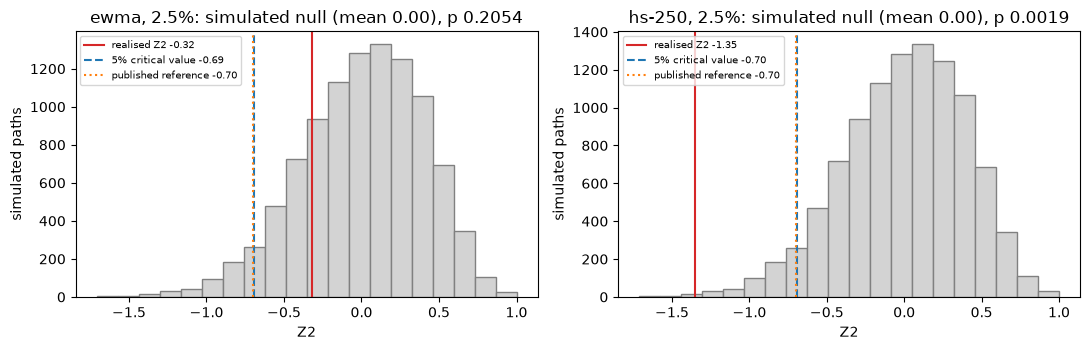

In [6]:
# Draw the committed simulated null of two models (histogram), the realised Z2, the 5% critical value and the published reference
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, mid in zip(axes, ("ewma", "hs-250")):
    row = committed_bt[(mid, 0.025)]
    edges, counts = np.array(row["histogram"]["edges"]), np.array(row["histogram"]["counts"])
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color="lightgrey", edgecolor="grey")
    ax.axvline(row["realised"], color="tab:red", label=f"realised Z2 {row['realised']:.2f}")
    ax.axvline(row["critical_5pct"], color="tab:blue", linestyle="--", label=f"5% critical value {row['critical_5pct']:.2f}")
    ax.axvline(reference["yellow"], color="tab:orange", linestyle=":", label="published reference -0.70")
    centre = float((counts * (edges[:-1] + edges[1:]) / 2).sum() / counts.sum())
    ax.set_title(f"{mid}, 2.5%: simulated null (mean {centre:.2f}), p {row['p_value']:.4f}")
    ax.set_xlabel("Z2")
    ax.set_ylabel("simulated paths")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

### Step 4: Du-Escanciano, a test built on the whole tail

$Z_2$ looks only at the exceedance days. Du and Escanciano (2017) use the **probability integral transform** (PIT) $u_t = F_t(y_t)$, the position of the realised return in the model's predictive distribution, which is uniform if the distribution is right. The cumulative violation process $H_t(lpha) = \frac{1}{\alpha}(\alpha - u_t)\,\mathbb 1\{u_t \le \alpha\}$ measures how deep into the $\alpha$-tail the observation fell: it is 0 outside the tail and grows to 1 at the extreme. Under correct forecasts $E[H_t] = \alpha/2$ and $\mathrm{Var}(H_t) = \alpha(1/3 - \alpha/4)$, which gives

$$U_{ES} = \frac{\sqrt{T}\,(\bar H - \alpha/2)}{\sqrt{\alpha(1/3-\alpha/4)}} \xrightarrow{d} N(0,1), \qquad C_{ES}(m) = T\sum_{j=1}^{m}\hat\rho_j^{\,2} \xrightarrow{d} \chi^2_m$$

where $\hat\rho_j$ are the autocorrelations of $H_t - \alpha/2$: the first statistic tests the level of the tail, the second whether tail violations come in sequences. Both need a predictive distribution, so the notebook uses two models whose distribution is a normal that the committed forecasts pin down. `ewma` has zero mean and a volatility the committed VaR fixes (step 4 of notebook 02). For `dn-rolling` the mean $\mu$ and volatility $\sigma$ are the two unknowns of the two delta-normal formulas $v = \mu + z\sigma$ and $e = \mu - \sigma\varphi(z)/\alpha$, which the cell inverts per day. The plain asymptotic tests ignore the uncertainty of the estimated parameters, as the engine's notes say. The committed C11 battery does not run these tests, so there are no committed rows to compare with.

In [7]:
# The predictive normal of ewma and dn-rolling from the committed VaR and ES, the PITs, and the Du-Escanciano tests
from riskvalidation.validation.market import du_escanciano_conditional, du_escanciano_unconditional

returns = -loss


def predictive_normal(model_id, alpha):
    """mu and sigma of the day's normal in the return convention, from the committed VaR and ES (loss numbers)."""
    level = [lv for lv in models[model_id]["by_level"] if lv["alpha"] == alpha][0]
    var, es = np.array(level["var"]), np.array(level["es"])
    z = stats.norm.ppf(alpha)
    if model_id == "ewma":                                   # zero mean: the VaR alone fixes sigma
        sigma = var / -z
        return np.zeros_like(sigma), sigma, var, es
    sigma = (es - var) / (stats.norm.pdf(z) / alpha + z)     # two unknowns, two equations
    return -var - z * sigma, sigma, var, es


pits = {}
for mid in ("ewma", "dn-rolling"):
    for alpha in (0.01, 0.025):
        mu, sigma, var, es = predictive_normal(mid, alpha)
        pit = stats.norm.cdf((returns - mu) / sigma)
        h = np.where(pit <= alpha, (alpha - pit) / alpha, 0.0)
        unconditional = du_escanciano_unconditional(pit, alpha, model_id=mid)
        conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id=mid)
        pits[(mid, alpha)] = pit
        print(f"{mid:10s} alpha {alpha:5.3f} | mean H {h.mean():.4f} vs alpha/2 {alpha / 2:.4f} | U_ES {unconditional.statistic:7.3f} p {unconditional.p_value:.4f} "
              f"{LIGHT[unconditional.light.value]:6s} | C_ES(5) {conditional.statistic:7.3f} p {conditional.p_value:.4f} {LIGHT[conditional.light.value]}")

ewma       alpha 0.010 | mean H 0.0091 vs alpha/2 0.0050 | U_ES   1.131 p 0.1291 green  | C_ES(5)  12.670 p 0.0267 red
ewma       alpha 0.025 | mean H 0.0150 vs alpha/2 0.0125 | U_ES   0.434 p 0.3323 green  | C_ES(5)  16.247 p 0.0062 red
dn-rolling alpha 0.010 | mean H 0.0736 vs alpha/2 0.0050 | U_ES  18.909 p 0.0000 red    | C_ES(5)   8.552 p 0.1283 green
dn-rolling alpha 0.025 | mean H 0.0969 vs alpha/2 0.0125 | U_ES  14.780 p 0.0000 red    | C_ES(5)  10.452 p 0.0634 amber


### Step 5: McNeil-Frey, the size of the excess over the ES

McNeil and Frey (2000) look at the exceedance days and ask whether the excess over the ES, scaled by the day's volatility, is zero on average: $r_t = (L_t - \mathrm{ES}_t)/\sigma_t$ should be independent with mean zero when the ES is right, and a positive mean means the ES is too low. The engine's `mcneil_frey_residual_test` takes the losses, VaR, ES and $\sigma_t$, and tests a zero mean with a one-sided bootstrap: the residuals centred at their mean are resampled and $p = (1 + \#\{\bar r^* \ge \bar r\})/(n_{boot}+1)$. It is a test of the **size** of the losses beyond the VaR that needs few assumptions, and it needs at least two exceedances. We run it with the $\sigma_t$ of step 4.

In [8]:
# The McNeil-Frey residual test on the exceedance days of the same two models, with the sigma of the previous step
from riskvalidation.validation.market import mcneil_frey_residual_test

for mid in ("ewma", "dn-rolling"):
    for alpha in (0.01, 0.025):
        mu, sigma, var, es = predictive_normal(mid, alpha)
        result = mcneil_frey_residual_test(loss, var, es, sigma, alpha, model_id=mid, n_boot=10000, seed=0)
        exceed = loss > var
        residuals = (loss[exceed] - es[exceed]) / sigma[exceed]
        print(f"{mid:10s} alpha {alpha:5.3f} | exceedances {result.n_events:2d} | mean residual {result.statistic:6.3f} "
              f"(range {residuals.min():.2f} to {residuals.max():.2f}) | bootstrap p {result.p_value:.4f} | light {LIGHT[result.light.value]}")

ewma       alpha 0.010 | exceedances  3 | mean residual  0.331 (range 0.00 to 0.93) | bootstrap p 0.0374 | light red
ewma       alpha 0.025 | exceedances  8 | mean residual  0.075 (range -0.37 to 1.25) | bootstrap p 0.3325 | light green
dn-rolling alpha 0.010 | exceedances 23 | mean residual  0.648 (range -0.28 to 2.29) | bootstrap p 0.0002 | light red
dn-rolling alpha 0.025 | exceedances 35 | mean residual  0.557 (range -0.38 to 2.62) | bootstrap p 0.0001 | light red


### Step 6: the same tests on a second window

A result on one window is an anecdote. The cell repeats the hand computation of $Z_2$ and the Du-Escanciano and McNeil-Frey tests for `ewma` in `rates-2022`, where the same two models are available in the same way, and sets them beside the committed $Z_2$ row. The point is the contrast between tests: on a given forecast they can disagree, and the validator reads them together.

In [9]:
# ewma in rates-2022: Z2 by hand and committed, Du-Escanciano and McNeil-Frey on the same forecast
rates = docs["rates-2022"]["outputs"]
rates_loss = np.array(rates["grid"]["realised_loss"]["loss"])
ewma_rates = {m["model_id"]: m for m in rates["models"]}["ewma"]
rates_bt = {(x["model_id"], x["alpha"]): x for x in rates["es_backtests"]}
for level in ewma_rates["by_level"]:
    alpha = level["alpha"]
    var, es = np.array(level["var"]), np.array(level["es"])
    exceed = rates_loss > var
    z2 = -(rates_loss[exceed] / es[exceed]).sum() / (rates_loss.size * alpha) + 1.0
    sigma = var / -stats.norm.ppf(alpha)                         # zero-mean normal: the VaR fixes sigma
    pit = stats.norm.cdf(-rates_loss / sigma)
    unconditional = du_escanciano_unconditional(pit, alpha, model_id="ewma")
    conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id="ewma")
    residual = mcneil_frey_residual_test(rates_loss, var, es, sigma, alpha, model_id="ewma", n_boot=10000, seed=0)
    row = rates_bt[("ewma", alpha)]
    print(f"alpha {alpha:5.3f} | exceedances {int(exceed.sum())} | Z2 {z2:.4f} (committed {row['realised']:.4f}, p {row['p_value']:.4f}) | "
          f"U_ES p {unconditional.p_value:.4f} {LIGHT[unconditional.light.value]} | C_ES p {conditional.p_value:.4f} | McNeil-Frey p {residual.p_value:.4f}")

alpha 0.010 | exceedances 6 | Z2 -1.5073 (committed -1.5073, p 0.0183) | U_ES p 0.0307 red | C_ES p 0.7818 | McNeil-Frey p 0.2841
alpha 0.025 | exceedances 9 | Z2 -0.5913 (committed -0.5913, p 0.0779) | U_ES p 0.0254 red | C_ES p 0.4295 | McNeil-Frey p 0.0993


## Results

- **Z1 and Z2 by hand.** 14 of the 17 models forecast an ES; the other three (`cf-rolling`, `caviar-sav`, `caviar-as`) cannot be tested. $Z_2$ computed from the definition equals the committed value for all 14 models at both levels, with a largest difference of 3.9e-08. The two statistics answer different questions. `hs-250` at 1 percent has $Z_1 = -0.0691$ (the ten exceedances were, on average, only slightly larger than the ES) and $Z_2 = -3.2592$ (there were ten of them where 2.51 were expected). `dn-rolling` has $Z_1 = -0.2444$ and $Z_2 = -10.4033$ with 23 exceedances.
- **The null reproduces.** With the null of step 2, the committed draws and the committed seed, the engine returns the committed p-value and the committed 5 percent critical value to the digits printed for the four models tried (for example `hs-250` at 1 percent: p 0.000200, critical value -1.0906). The smallest p-value a run can give is $1/(n_{sim}+1) = 0.0001$, which is what the red models show.
- **A critical value per model.** At 2.5 percent the 5 percent critical value runs from -0.723 to -0.687 across the 14 models, and the published -0.70 lies inside that range; the 0.01 percent value runs from -1.762 to -1.559, less negative than the published -1.8. At 1 percent the values are far from the reference: -1.211 to -1.056 at 5 percent and -3.587 to -2.854 at 0.01 percent. The published pair is a reference for one level and sample size, and the simulated values depend on both, and on the model.
- **The lights at 2.5 percent.** Green: `ewma`, the three GARCH, `fhs`, `evt-mf`, `caviar-es` and `gas-fz-1`; amber: `hs-250` (p 0.0019) and `awhs` (p 0.038); red: `hs-500`, `dn-rolling`, `gas-fz-2` and `gas-hybrid` (p at the 0.0001 floor). The null of the figure is centred near 0 for both models, and the realised $Z_2$ of `hs-250` lies far to its left of the 5 percent critical value while that of `ewma` lies inside.
- **Du-Escanciano.** For `ewma` in `fx-2008` the unconditional test does not reject (p 0.129 at 1 percent and 0.332 at 2.5 percent), but the conditional test does (p 0.0267 and 0.0062): the cumulative violations come in sequences, which $Z_2$ (p 0.256 and 0.205, green) cannot see. For `dn-rolling` the level is wrong: the mean of $H_t$ is 0.0736 against 0.0050 expected at 1 percent, and $U_{ES}$ is 18.9.
- **McNeil-Frey.** `dn-rolling` has a mean standardised excess of 0.648 over 23 exceedances at 1 percent (bootstrap p 0.0002) and 0.557 over 35 at 2.5 percent: the losses beyond the VaR are about half a daily volatility above the ES it forecast. `ewma` at 1 percent is red with only 3 exceedances (mean 0.331, p 0.0374), a result that rests on three residuals.
- **A second window.** For `ewma` in `rates-2022`, $Z_2$ by hand equals the committed value (-1.5073 and -0.5913, p 0.0183 and 0.0779), yet the unconditional Du-Escanciano test is red at both levels (p 0.0307 and 0.0254). The tests are not redundant.

What this notebook does not show: how to choose between models that pass all of them (notebook 05).

## Summary

- A VaR backtest counts exceedances; an ES backtest must look at the size of the losses beyond the VaR. $Z_1$ does so on the exceedance days, $Z_2$ also penalises a wrong number of them, and both are zero under correct forecasts and negative when risk is underestimated.
- A critical value needs a null. The engine asks the caller for it; Contraste supplies one tail-consistent null for every rung (an exponential excess with mean $\mathrm{ES} - \mathrm{VaR}$), so each model's critical values come from its own VaR and ES path, under a stated assumption about the shape of the tail.
- The published $-0.70$ and $-1.8$ are a reference point for $T = 250$ and $\alpha = 2.5$ percent, verified only through a secondary source; the committed critical values differ by model and level.
- Du-Escanciano uses the whole predictive distribution through the PIT, McNeil-Frey the size of the excess over the ES; they need a predictive distribution or a volatility, and on one forecast they can disagree with $Z_2$.
- None of these tests replaces the count tests of notebook 03; the eligibility gates of the ladder use Kupiec, conditional coverage and $Z_2$ together.

**What to try next.** Change `n_sim` in step 2 to 1000 and watch the p-value and the 0.01 percent critical value (which needs at least 10,000 draws to resolve); then read notebook 05, which ranks the models that pass.

## References

- Acerbi, C. and Szekely, B. (2014), Backtesting expected shortfall, Risk, December 2014 (primary text not retrieved). The reference point of -0.70 and -1.8 is read through Moldenhauer, G. and Pitera, M. (2017), Backtesting expected shortfall, section 6. https://arxiv.org/abs/1709.01337
- Du, Z. and Escanciano, J. C. (2017), Backtesting expected shortfall: accounting for tail risk, Management Science 63(4). https://doi.org/10.1287/mnsc.2015.2342
- McNeil, A. J. and Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Nolde, N. and Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041